<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/code/01RAD_Ex06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Exercise 06: Testing in the Multiple Model: $F$-tests, the General Linear Hypothesis, Prediction

Model $(\ast\ast)$: $\mathbf{Y} = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}$, $h(\mathbf{X}) = m+1$; for tests and intervals $\mathbf{e} \sim N_n(\mathbf{0}, \sigma^2\mathbf{I}_n)$. Slides `lectures/01RAD_2024.pdf`, pp. 86–106:
- **overall $F$-test** (celkový $F$-test, Theorem 3.9), **ANOVA table** (tabulka ANOVA), $R^2$ and **adjusted $R^2$** (upravený koeficient determinace), pp. 86–88,
- $t$-tests in practice: a significant model without significant coefficients (Examples 3.3–3.5, pp. 89–94),
- **general linear hypothesis** (obecná lineární hypotéza) $H_0: \mathbf{C}\boldsymbol{\beta} = \mathbf{b}$, full and reduced model, **extra sum of squares** (Theorem 3.10, Lemma 3.2, pp. 95–101),
- **prediction** (predikce): interval for $\mathsf E\,Y_{\mathbf{x}_0}$, prediction interval, extrapolation (pp. 102–106).

R equivalents in brackets.

## Learning goals
- ANOVA table of a multiple model by hand; $F$, $p$-value, $R^2$, $R^2_{adj}$ matched with `summary()`.
- What $R^2_{adj}$ corrects and what it does not.
- Significant model, insignificant coefficients: correlated regressors, VIF, confidence ellipse.
- Any hypothesis about $\boldsymbol{\beta}$ as $\mathbf{C}\boldsymbol{\beta} = \mathbf{b}$; test by full vs. reduced model and by Lemma 3.2.
- Sequential ANOVA table (R `anova`, statsmodels `anova_lm`) depends on the order of the terms.
- CI for $\mathsf E\,Y_{\mathbf{x}_0}$ and prediction interval in matrix form; extrapolation via $\mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0$.
- Before any test or interval: look at the data and the residuals.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from patsy import dmatrices, dmatrix

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.precision', 4)
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(2026)

In [2]:
url_mpg = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/mpg.csv'
try:
    mpg_raw = pd.read_csv(url_mpg)
except Exception:
    mpg_raw = sns.load_dataset('mpg')          # the same data set ships with seaborn
cars = mpg_raw.dropna().reset_index(drop=True)
cars['l_per_100km'] = 235.215 / cars['mpg']        # fuel consumption, as in Exercises 03 and 05

# Examples 3.2-3.4 of the slides: birth weight (g) and gestational age (weeks)
birth = pd.DataFrame({
    'Weight': [2968, 2795, 3163, 2925, 2625, 2847, 3292, 3473, 2628, 3176, 3421, 2975,
               3317, 2729, 2935, 2754, 3210, 2817, 3126, 2539, 2412, 2991, 2875, 3231],
    'Age': [40, 38, 40, 35, 36, 37, 41, 40, 37, 38, 40, 38, 40, 36, 40, 38, 42, 39, 40, 37, 36, 38, 39, 40],
    'Sex': ['boy'] * 12 + ['girl'] * 12})

# Example 3.5 of the slides: heat of hardening of cement (y, cal/g) and four ingredients (x1-x4, % of weight)
cement = pd.DataFrame({
    'x1': [7, 1, 11, 11, 7, 11, 3, 1, 2, 21, 1, 11, 10],
    'x2': [26, 29, 56, 31, 52, 55, 71, 31, 54, 47, 40, 66, 68],
    'x3': [6, 15, 8, 8, 6, 9, 17, 22, 18, 4, 23, 9, 8],
    'x4': [60, 52, 20, 47, 33, 22, 6, 44, 22, 26, 34, 12, 12],
    'y': [78.5, 74.3, 104.3, 87.6, 95.9, 109.2, 102.7, 72.5, 93.1, 115.9, 83.8, 113.3, 109.4]})
print(f'{len(cars)} cars, {len(birth)} newborns, {len(cement)} cement samples')


def residual_maker(Z):
    """Residuals of the projection onto the columns of Z, as a function (Exercise 04)."""
    Q_z, _ = np.linalg.qr(Z)
    return lambda v: v - Q_z @ (Q_z.T @ v)


def residual_plots(fit, data, variables, order_name='observation order'):
    """Histogram, Q-Q plot and r_i against fitted values, order and variables (Exercise 05)."""
    r = fit.get_influence().resid_studentized_internal
    k = len(r)
    panels = [('fitted values', np.asarray(fit.fittedvalues)), (order_name, np.arange(k))] + \
             [(v, data[v].to_numpy(dtype=float)) for v in variables]
    ncol = 4
    nrow = int(np.ceil((2 + len(panels)) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(20, 3.8 * nrow))
    axes = axes.ravel()
    axes[0].hist(r, bins=30 if k >= 100 else 8, density=True, color='lightsteelblue')
    g = np.linspace(-4, 4, 200)
    axes[0].plot(g, stats.norm.pdf(g), color='darkred')
    axes[0].set_title('histogram of $\\widehat{r}_i$')
    q = stats.norm.ppf((np.arange(1, k + 1) - 0.5) / k)
    axes[1].scatter(q, np.sort(r), s=8)
    axes[1].plot([-3.5, 3.5], [-3.5, 3.5], color='darkred')
    axes[1].set_title('Q-Q plot'); axes[1].set_xlabel('normal quantiles')
    for ax, (lab, vals) in zip(axes[2:], panels):
        ax.scatter(vals, r, s=8, alpha=0.6)
        ax.axhline(0, color='darkred')
        for b in (-2, 2):
            ax.axhline(b, color='gray', ls=':')
        if k >= 50:                                         # a smoother needs enough points
            smooth = sm.nonparametric.lowess(r, vals, frac=0.3)
            ax.plot(smooth[:, 0], smooth[:, 1], color='orange', lw=2)
        ax.set_xlabel(lab); ax.set_title(f'$\\widehat{{r}}_i$ vs {lab}')
    for ax in axes[2 + len(panels):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def anova_table(fit):
    """Overall ANOVA table of a model with an intercept (slides p. 87)."""
    y = fit.model.endog
    n_, m_ = len(y), int(fit.df_model)
    SST = np.sum((y - y.mean()) ** 2)
    SSE = np.sum(fit.resid ** 2)
    SSR = SST - SSE
    F = (SSR / m_) / (SSE / (n_ - m_ - 1))
    return pd.DataFrame({'df': [m_, n_ - m_ - 1, n_ - 1], 'SS': [SSR, SSE, SST],
                         'MS': [SSR / m_, SSE / (n_ - m_ - 1), np.nan], 'F': [F, np.nan, np.nan],
                         'p-value': [stats.f.sf(F, m_, n_ - m_ - 1), np.nan, np.nan]},
                        index=['Regression', 'Residual', 'Total'])


def vif_table(fit):
    """Variance inflation factors 1 / (1 - R_j^2) of the regressors (R: car::vif)."""
    X_ = fit.model.exog
    return pd.Series([variance_inflation_factor(X_, j) for j in range(1, X_.shape[1])],
                     index=fit.model.exog_names[1:], name='VIF')

392 cars, 24 newborns, 13 cement samples


## 2. Solution of the individual work from Exercise 05
`Credit.csv`: `Balance` (USD) of 400 card holders. Numbers in the text are those of the executed cells.

**Step 1.** Factors and zero balances.

In [3]:
url_credit = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/Credit.csv'
credit = pd.read_csv(url_credit, index_col=0)
for col in ['Gender', 'Student', 'Married', 'Ethnicity']:
    print(f'{col:10s}', credit[col].map(repr).value_counts().to_dict())       # repr shows hidden spaces
credit['Gender'] = credit['Gender'].str.strip()
print(f'\nBalance == 0: {(credit["Balance"] == 0).sum()} of {len(credit)}')
credit.groupby(credit['Balance'] == 0)[['Income', 'Limit', 'Rating']].mean().rename(index={False: 'Balance > 0', True: 'Balance = 0'})

Gender     {"'Female'": 207, "' Male'": 193}
Student    {"'No'": 360, "'Yes'": 40}
Married    {"'Yes'": 245, "'No'": 155}
Ethnicity  {"'Caucasian'": 199, "'Asian'": 102, "'African American'": 99}

Balance == 0: 90 of 400


,Income,Limit,Rating
Balance,,,
Balance > 0,49.9788,5485.4677,405.0516
Balance = 0,28.8236,2152.7222,182.3333


- `Gender`: level `' Male'` with a leading space; `== 'Male'` selects nobody. Check levels with `repr` / `unique()`.
- 90 people (22.5 %) have `Balance = 0`, with much lower limits and ratings: the response is bounded by zero (Step 6).

**Step 2.** Parallel lines and interaction.

,coef parallel,se parallel,coef interaction,se interaction,p interaction
Intercept,211.1430,32.4572,200.6232,33.6984,5.7897e-09
Student[T.Yes],382.6705,65.3108,476.6758,104.3512,6.5861e-06
Income,5.9843,0.5566,6.2182,0.5921,6.3407e-23
Income:Student[T.Yes],NaN,NaN,-1.9992,1.7313,2.4889e-01


interaction model: non-students 200.6 + 6.218 Income,  students 677.3 + 4.219 Income
R^2: 0.2775 vs 0.2799


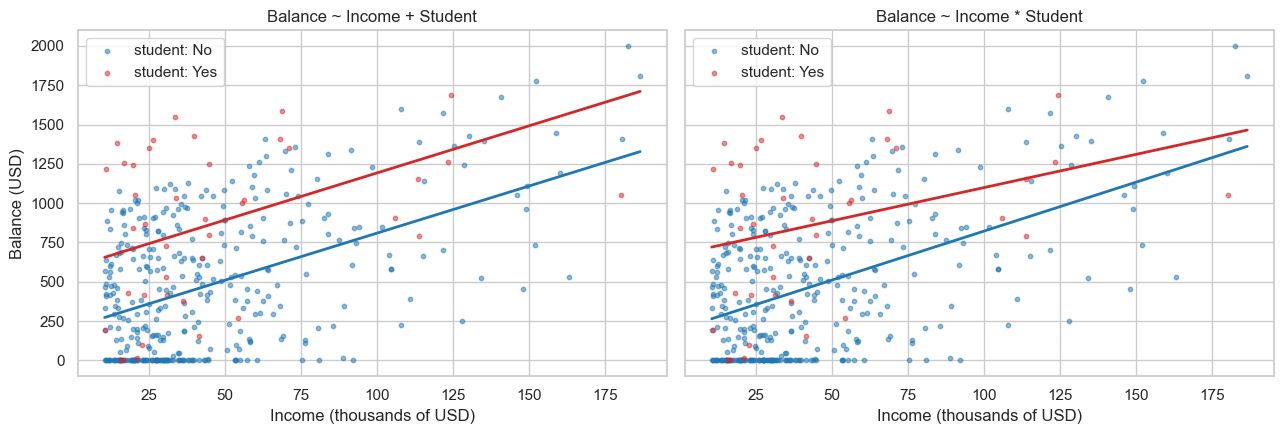

In [4]:
cr_par = smf.ols('Balance ~ Income + Student', data=credit).fit()       # R: lm(Balance ~ Income + Student)
cr_int = smf.ols('Balance ~ Income * Student', data=credit).fit()       # R: lm(Balance ~ Income * Student)
display(pd.DataFrame({'coef parallel': cr_par.params, 'se parallel': cr_par.bse,
                      'coef interaction': cr_int.params, 'se interaction': cr_int.bse,
                      'p interaction': cr_int.pvalues}).loc[cr_int.params.index])
c_ = cr_int.params
print(f'interaction model: non-students {c_["Intercept"]:.1f} + {c_["Income"]:.3f} Income,'
      f'  students {c_["Intercept"] + c_["Student[T.Yes]"]:.1f} + {c_["Income"] + c_["Income:Student[T.Yes]"]:.3f} Income')
print(f'R^2: {cr_par.rsquared:.4f} vs {cr_int.rsquared:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
inc = np.linspace(credit['Income'].min(), credit['Income'].max(), 50)
for ax, fit, title in [(axes[0], cr_par, 'Balance ~ Income + Student'), (axes[1], cr_int, 'Balance ~ Income * Student')]:
    for st, col in [('No', 'tab:blue'), ('Yes', 'tab:red')]:
        d_ = credit[credit['Student'] == st]
        ax.scatter(d_['Income'], d_['Balance'], s=10, alpha=0.5, color=col, label=f'student: {st}')
        ax.plot(inc, fit.predict(pd.DataFrame({'Income': inc, 'Student': st})), color=col, lw=2)
    ax.set_xlabel('Income (thousands of USD)'); ax.set_title(title); ax.legend()
axes[0].set_ylabel('Balance (USD)')
plt.tight_layout()
plt.show()

- Parallel: non-students $211 + 5.98\cdot\text{Income}$, students $+383$ USD at the same income.
- Interaction: non-students $200.6 + 6.22\cdot\text{Income}$, students $677.3 + 4.22\cdot\text{Income}$; `Student[T.Yes]` is now the difference at zero income.
- $t$-test of the interaction: $t \approx -1.15$, $p \approx 0.25$; no evidence for different slopes (only 40 students).
- $R^2 < 0.3$: income and student status alone predict the balance poorly.

**Step 3.** Three levels, reference level, the factor as a whole.

In [5]:
eth1 = smf.ols('Balance ~ Income + Ethnicity', data=credit).fit()
eth2 = smf.ols('Balance ~ Income + C(Ethnicity, Treatment("Caucasian"))', data=credit).fit()   # R: relevel(Ethnicity, ref = "Caucasian")
display(pd.concat({'reference African American': eth1.params, 'reference Caucasian': eth2.params}, axis=1))
print(f'max |fitted difference| = {np.abs(eth1.fittedvalues - eth2.fittedvalues).max():.1e}')
display(anova_lm(smf.ols('Balance ~ Income', data=credit).fit(), eth1))        # R: anova(lm(Balance ~ Income), mod)

,reference African American,reference Caucasian
Intercept,242.4882,249.1069
Ethnicity[T.Asian],2.4566,NaN
Ethnicity[T.Caucasian],6.6188,NaN
Income,6.0507,6.0507
"C(Ethnicity, Treatment(""Caucasian""))[T.African American]",NaN,-6.6188
"C(Ethnicity, Treatment(""Caucasian""))[T.Asian]",NaN,-4.1621


max |fitted difference| = 1.8e-12


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,398.0,6.6209e+07,0.0,NaN,NaN,NaN
1,396.0,6.6206e+07,2.0,3186.292,0.0095,0.9905


- Default reference: first level alphabetically (`African American`). Changing it moves the intercept and the dummies; differences between groups, fitted values, $s_n$, $R^2$ stay.
- Ethnicity as a whole ($H_0$: both dummies zero, Section 6): $F = 0.01$, $p = 0.99$, the same for any reference level.

**Step 4.** Standard errors by hand, correlation of the estimates.

In [6]:
cr_full = smf.ols('Balance ~ Income + Limit + Rating + Student', data=credit).fit()
yc_df, Xc_df = dmatrices('Balance ~ Income + Limit + Rating + Student', data=credit, return_type='dataframe')
Xc_ = Xc_df.to_numpy()
yc_ = yc_df.to_numpy().ravel()
XtX_inv_c = np.linalg.inv(Xc_.T @ Xc_)
s2_c = np.sum(cr_full.resid ** 2) / (Xc_.shape[0] - Xc_.shape[1])
display(pd.DataFrame({'coef': cr_full.params, 'se manual': np.sqrt(s2_c * np.diag(XtX_inv_c)), 'se statsmodels': cr_full.bse}))
cov_c = pd.DataFrame(s2_c * XtX_inv_c, index=Xc_df.columns, columns=Xc_df.columns)
corr_LR = cov_c.loc['Limit', 'Rating'] / np.sqrt(cov_c.loc['Limit', 'Limit'] * cov_c.loc['Rating', 'Rating'])
print(f'corr of the estimates Limit, Rating: {corr_LR:.3f};  corr of the regressors: {credit["Limit"].corr(credit["Rating"]):.4f}')
cr_noR = smf.ols('Balance ~ Income + Limit + Student', data=credit).fit()
print(f'se(Limit): {cr_full.bse["Limit"]:.4f} with Rating, {cr_noR.bse["Limit"]:.4f} without;  VIF of Limit = {vif_table(cr_full)["Limit"]:.0f}')

,coef,se manual,se statsmodels
Intercept,-516.7183,20.0055,20.0055
Student[T.Yes],422.6684,16.8738,16.8738
Income,-7.9446,0.2355,0.2355
Limit,0.1217,0.0279,0.0279
Rating,2.1904,0.4149,0.4149


corr of the estimates Limit, Rating: -0.992;  corr of the regressors: 0.9969
se(Limit): 0.0279 with Rating, 0.0037 without;  VIF of Limit = 162


- Manual $s_n\sqrt{v_j}$ = `bse`.
- `Limit` and `Rating`: regressors correlated $0.997$, estimates $-0.992$. The data cannot separate them.
- Without `Rating` the standard error of `Limit` drops about 7.5 times: the **variance inflation factor** $1/(1-R_j^2)$ (Section 4.3; collinearity chapter later).

**Step 5.** The sign of `Income`.

In [7]:
cr_simple = smf.ols('Balance ~ Income', data=credit).fit()
M_c = residual_maker(Xc_df[['Intercept', 'Student[T.Yes]', 'Limit', 'Rating']].to_numpy())   # all regressors but Income
inc_t, bal_t = M_c(Xc_df['Income'].to_numpy()), M_c(yc_)
print(f'Income: simple {cr_simple.params["Income"]:.3f}, multiple {cr_full.params["Income"]:.3f}, FWL {(inc_t @ bal_t) / (inc_t @ inc_t):.3f}')

Income: simple 6.048, multiple -7.945, FWL -7.945


- Simple $+6.05$, multiple $-7.94$: higher income goes with higher limits and thus higher balances; **at the same limit and rating** more income means a lower balance.
- Two different questions (all else free vs. all else fixed), not a contradiction.

**Step 6.** Residuals.

sum e_i = -1.3e-07,  negative fitted balances: 64


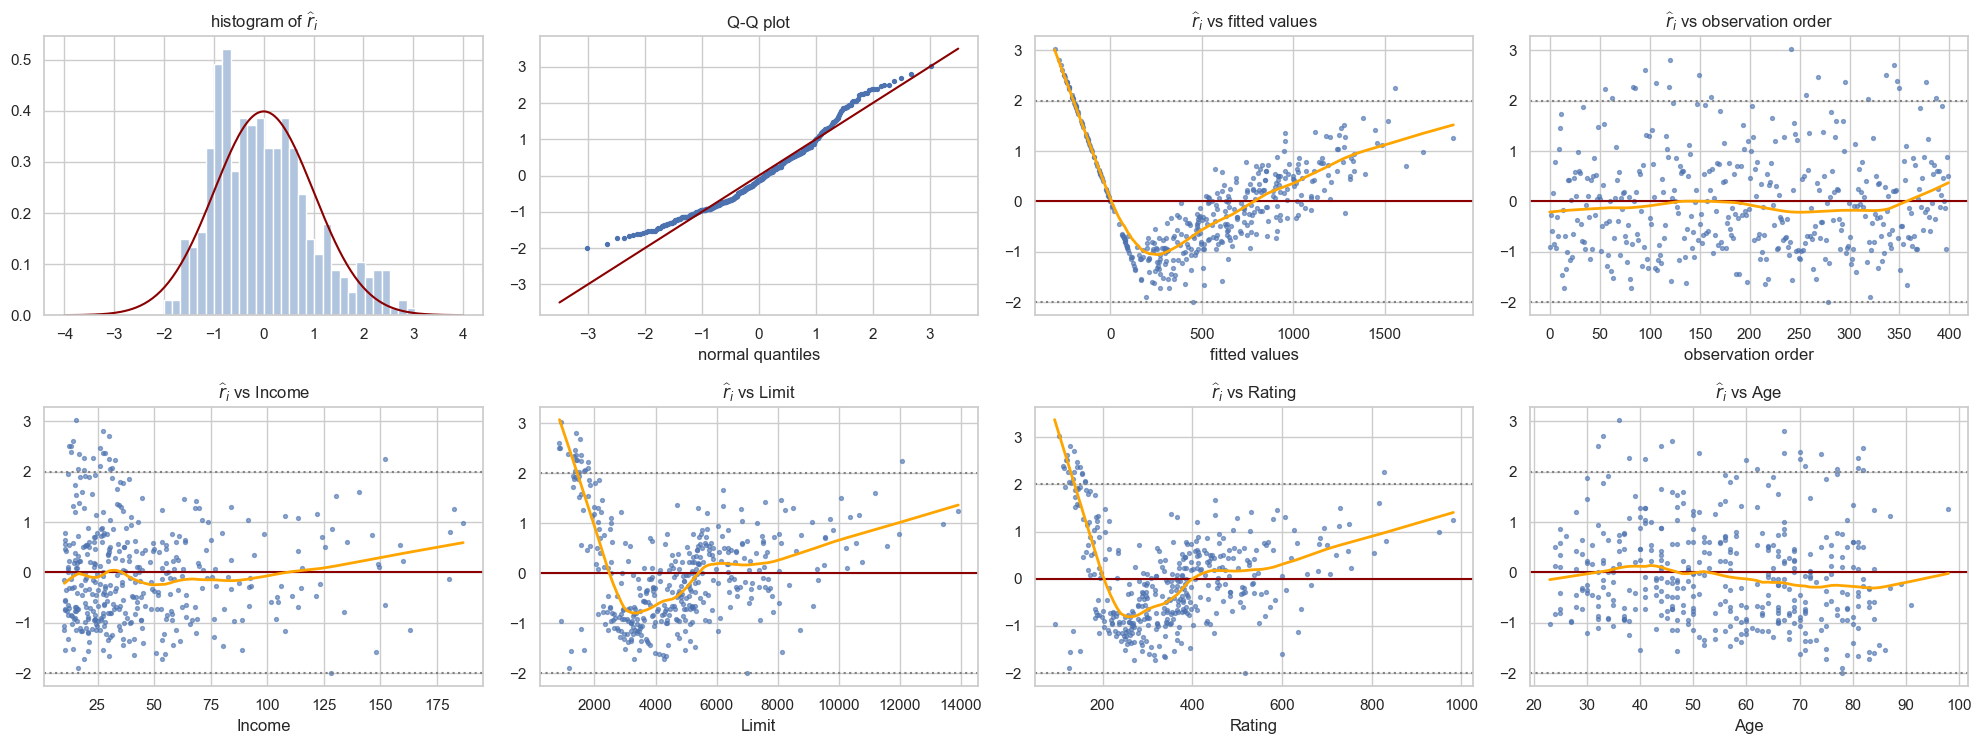

In [8]:
print(f'sum e_i = {cr_full.resid.sum():.1e},  negative fitted balances: {(cr_full.fittedvalues < 0).sum()}')
residual_plots(cr_full, credit, ['Income', 'Limit', 'Rating', 'Age'])

- Not a band but a **V**: the straight edge on the left are the 90 zero balances ($\widehat{e}_i = -\widehat{y}_i$); the model predicts negative balances for 64 people.
- The zeros cause the "curvature" in `Limit` and `Rating`. Fit the same model to the positive balances only:

Balance > 0: n = 310, R^2 = 0.9923, s_n = 36.5  (all data: R^2 = 0.9522, s_n = 101.0)


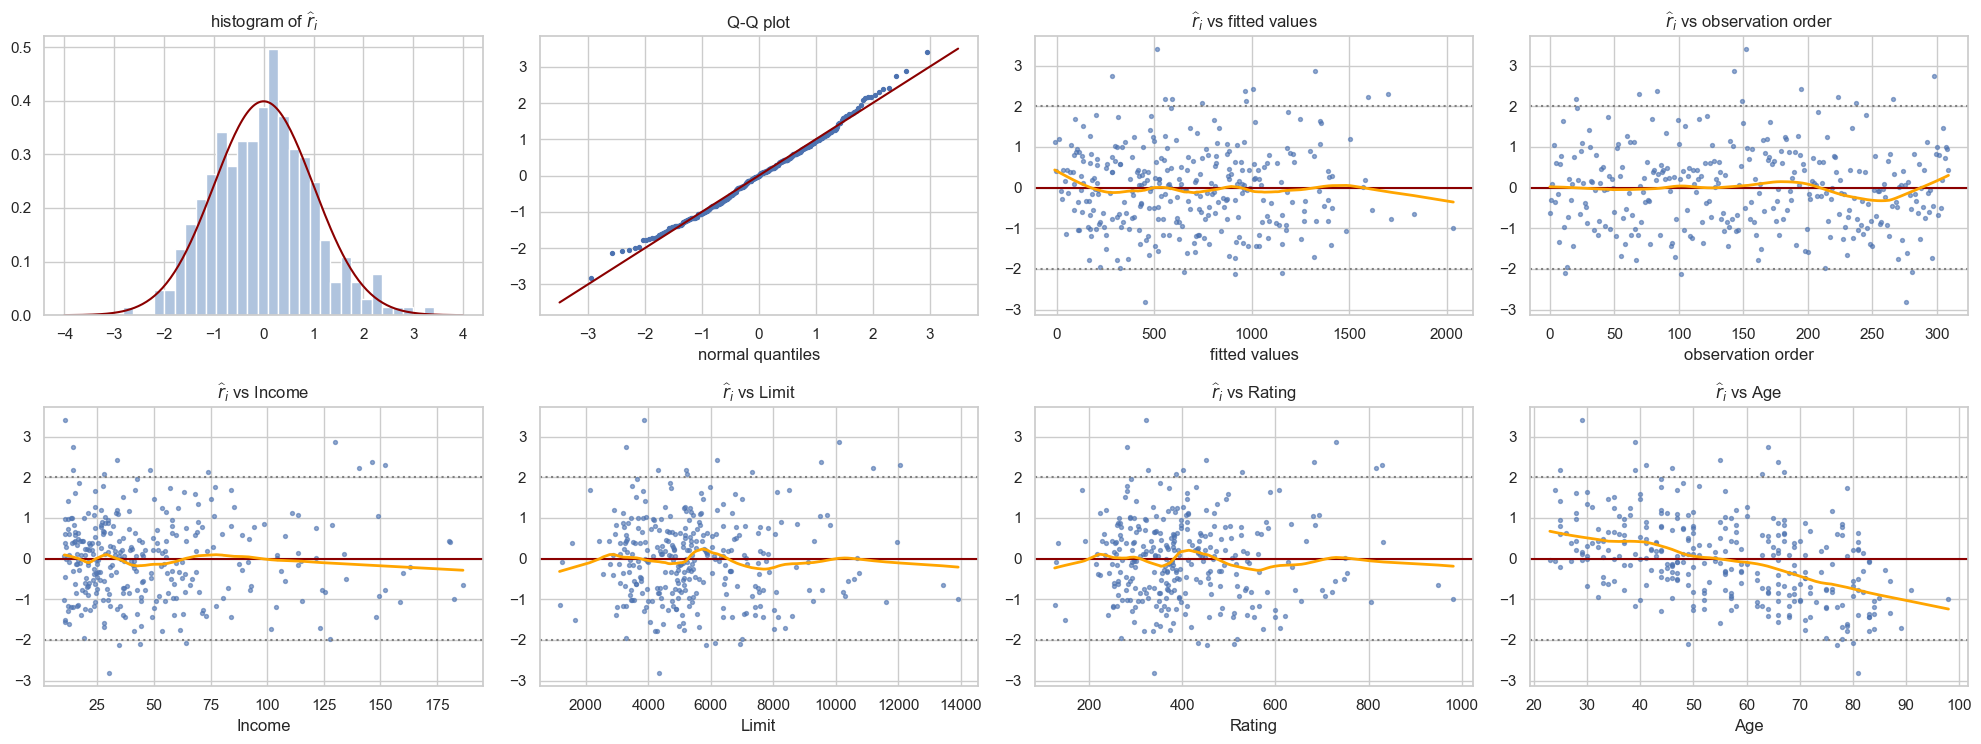

In [9]:
credit_pos = credit[credit['Balance'] > 0]
cr_pos = smf.ols('Balance ~ Income + Limit + Rating + Student', data=credit_pos).fit()
print(f'Balance > 0: n = {len(credit_pos)}, R^2 = {cr_pos.rsquared:.4f}, s_n = {np.sqrt(cr_pos.scale):.1f}  (all data: R^2 = {cr_full.rsquared:.4f}, s_n = {np.sqrt(cr_full.scale):.1f})')
residual_plots(cr_pos, credit_pos, ['Income', 'Limit', 'Rating', 'Age'])

- Among positive balances the relationship is linear: $R^2 = 0.992$, $s_n$ drops from about 100 to 37 USD.
- One structure remains: a clear downward trend against `Age`, which is not in the model (older people have smaller balances at the same limit).
- Two questions: *who has a zero balance* (almost determined by a low `Rating`) and *how large is a positive balance* (a linear model).
- A fit this good is rare for real debts: the textbook data are most likely constructed. Tests of this exercise assume a correct model; for all 400 people they would not be trustworthy.

## 3. The overall $F$-test and the ANOVA table
### 3.1 Theorem 3.9 and the table (pp. 86–87)
- $H_0: \beta_1 = \dots = \beta_m = 0$. Under $H_0$ and i.i.d. $N(0, \sigma^2)$ errors: $\ F = \dfrac{\mathrm{SSR}/m}{\mathrm{SSE}/(n-m-1)} = \dfrac{\mathrm{MSR}}{\mathrm{MSE}} \sim F(m, n-m-1)$.
- Reject if $F > F_{1-\alpha}(m, n-m-1)$. R: last line of `summary(lm(...))`; statsmodels `fvalue`, `f_pvalue`.
- $m = 1$: the table of Exercise 03, $F = T_1^2$.

| source | df | SS | MS | $F$ |
|---|---|---|---|---|
| Regression | $m$ | $\mathrm{SSR}$ | $\mathrm{MSR} = \mathrm{SSR}/m$ | $\mathrm{MSR}/\mathrm{MSE}$ |
| Residual | $n-m-1$ | $\mathrm{SSE}$ | $\mathrm{MSE} = s_n^2$ | |
| Total | $n-1$ | $\mathrm{SST}$ | | |

- **Naming trap in statsmodels:** `ssr` = our $\mathrm{SSE}$ (sum of squared residuals), `ess` = our $\mathrm{SSR}$, `centered_tss` = $\mathrm{SST}$.

Model: fuel consumption (L/100 km) on weight and horsepower. Exercise 05, Section 5.4: with `mpg` as the response the residuals are U-shaped, with L/100 km they are not. Check first:

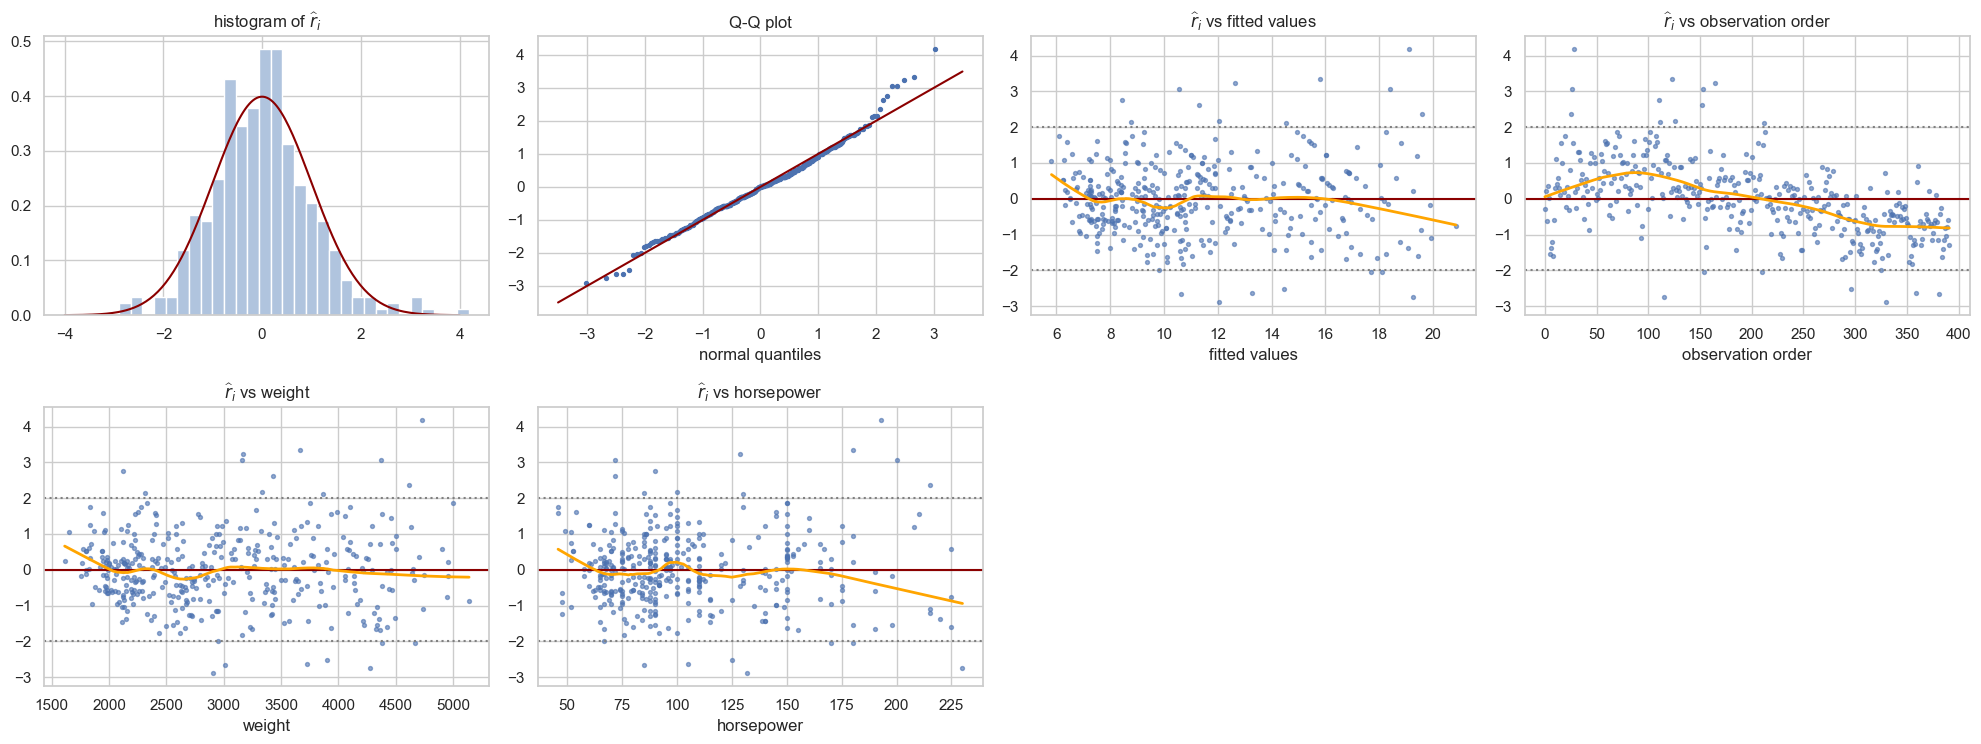

,df,SS,MS,F,p-value
Regression,2,4882.2130,2441.1065,857.6521,2.5153e-143
Residual,389,1107.1977,2.8463,NaN,NaN
Total,391,5989.4107,NaN,NaN,NaN


statsmodels: F = 857.7, p = 2.5e-143;  ess = 4882.2 (SSR), ssr = 1107.2 (SSE)
F_0.95(2, 389) = 3.02;  R^2 = 0.815, s_n = 1.69 L/100 km


In [10]:
model = smf.ols('l_per_100km ~ weight + horsepower', data=cars).fit()      # R: lm(l_per_100km ~ weight + horsepower)
residual_plots(model, cars, ['weight', 'horsepower'])
display(anova_table(model))
print(f'statsmodels: F = {model.fvalue:.1f}, p = {model.f_pvalue:.1e};  ess = {model.ess:.1f} (SSR), ssr = {model.ssr:.1f} (SSE)')
print(f'F_0.95(2, {int(model.df_resid)}) = {stats.f.ppf(0.95, 2, model.df_resid):.2f};  R^2 = {model.rsquared:.3f}, s_n = {np.sqrt(model.scale):.2f} L/100 km')

- Against weight, horsepower, fitted values: no curvature (with `mpg` there was a U); the spread grows slightly with the consumption.
- Against the order (the data are sorted by model year): a clear trend, newer cars use less fuel. `model_year` is missing (Exercise 05, Section 5.4); we keep two regressors so that the pictures of Section 7 stay two-dimensional.
- $F \approx 858 \gg F_{0.95} = 3.02$: weight and power together explain the consumption. Expected; the overall test protects against multiple testing (Exercise 05, Section 6) and is the template for Section 6.

### 3.2 $F$ under $H_0$, normal and skewed errors
- Fixed $\mathbf{X}$ of the model above, $\beta_1 = \beta_2 = 0$, 5000 data sets.
- Remark p. 87: without normality the test is justified for large $n$ by the CLT. Check with centered exponential errors.

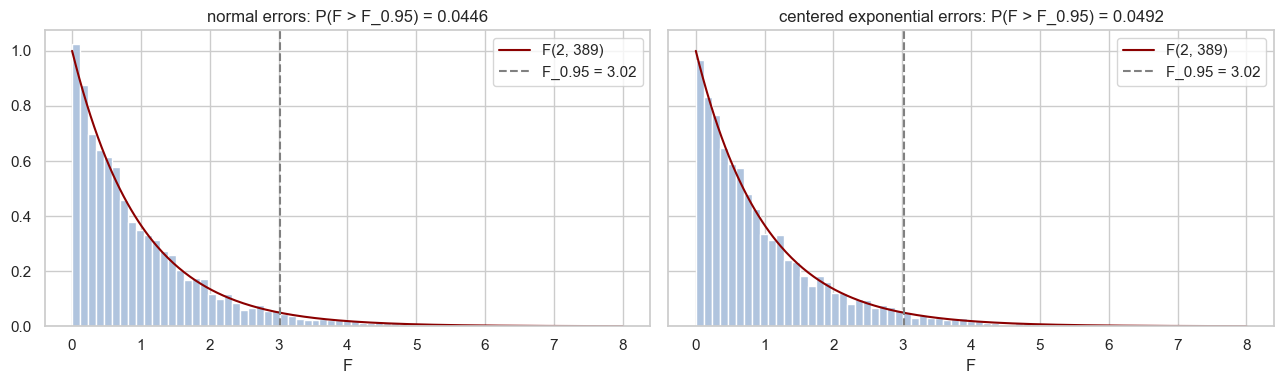

Monte Carlo error of a rejection rate near 0.05: +- 0.0062


In [11]:
y_df, X_df = dmatrices('l_per_100km ~ weight + horsepower', data=cars, return_type='dataframe')
X = X_df.to_numpy()
n, p = X.shape
m = p - 1
sigma = np.sqrt(model.scale)
beta_H0 = np.array([model.params['Intercept'], 0.0, 0.0])
n_sim = 5000


def simulate_F(errors):
    Y = X @ beta_H0 + sigma * errors                                   # n_sim x n
    B = np.linalg.lstsq(X, Y.T, rcond=None)[0].T
    fitted = B @ X.T
    SSE = np.sum((Y - fitted) ** 2, axis=1)
    SSR = np.sum((fitted - Y.mean(axis=1, keepdims=True)) ** 2, axis=1)
    return (SSR / m) / (SSE / (n - m - 1))


F_norm = simulate_F(rng.standard_normal((n_sim, n)))
F_exp = simulate_F(rng.exponential(1.0, (n_sim, n)) - 1)             # mean 0, variance 1, skewed
crit = stats.f.ppf(0.95, m, n - m - 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
g = np.linspace(0, 8, 300)
for ax, F_sim, title in [(axes[0], F_norm, 'normal errors'), (axes[1], F_exp, 'centered exponential errors')]:
    ax.hist(F_sim, bins=np.linspace(0, 8, 70), density=True, color='lightsteelblue')
    ax.plot(g, stats.f.pdf(g, m, n - m - 1), color='darkred', label=f'F({m}, {n - m - 1})')
    ax.axvline(crit, color='gray', ls='--', label=f'F_0.95 = {crit:.2f}')
    ax.set_title(f'{title}: P(F > F_0.95) = {np.mean(F_sim > crit):.4f}'); ax.set_xlabel('F'); ax.legend()
plt.tight_layout()
plt.show()
print(f'Monte Carlo error of a rejection rate near 0.05: +- {2 * np.sqrt(0.05 * 0.95 / n_sim):.4f}')

- Both follow $F(2, 389)$, both keep 5 % within the Monte Carlo error.
- With $n = 392$ skewness does not matter; with ten observations it would (Exercise 05, Section 8.1).

### 3.3 $R^2$ and $R^2_{adj}$ (Remark 3.6, p. 88)
- $R^2 = \mathrm{SSR}/\mathrm{SST}$ never decreases with a new variable, useful or not; $n$ independent columns give a perfect fit (**overfitting**, přeučení).
- $R^2_{adj} = 1 - \dfrac{\mathrm{SSE}/(n-m-1)}{\mathrm{SST}/(n-1)} = 1 - s_n^2/s_y^2$ (R: `Adjusted R-squared`, statsmodels `rsquared_adj`).
- Adding one variable increases $R^2_{adj}$ exactly when its $|t| > 1$ (a much weaker condition than $|t| > 2$).
- Experiment: `Weight ~ Age + Sex` ($n = 24$) plus $k$ columns of pure noise, 500 noise draws.

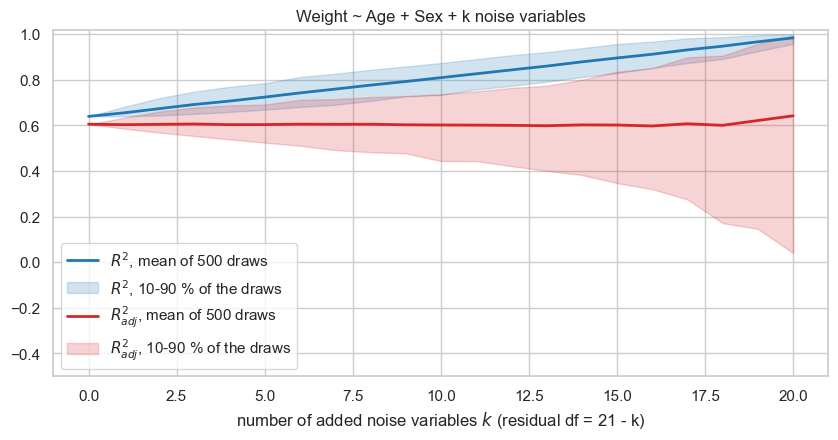

k = 0: R^2 = 0.640, R^2_adj = 0.606;  k = 20: mean R^2 = 0.984, mean R^2_adj = 0.642, 10-90 % of R^2_adj: 0.04 to 0.99


In [12]:
y_b, X_b0 = dmatrices('Weight ~ Age + Sex', data=birth, return_type='dataframe')
y_b = y_b.to_numpy().ravel()
X_b0 = X_b0.to_numpy()
n_b = len(y_b)
SST_b = np.sum((y_b - y_b.mean()) ** 2)
ks = np.arange(0, 21)
R2 = np.zeros((500, len(ks)))
R2adj = np.zeros_like(R2)
for rep in range(500):
    Z = rng.standard_normal((n_b, ks.max()))
    for col, k in enumerate(ks):
        Xk = np.column_stack([X_b0, Z[:, :k]])
        e_k = y_b - Xk @ np.linalg.lstsq(Xk, y_b, rcond=None)[0]
        R2[rep, col] = 1 - e_k @ e_k / SST_b
        R2adj[rep, col] = 1 - (e_k @ e_k / (n_b - Xk.shape[1])) / (SST_b / (n_b - 1))

fig, ax = plt.subplots(figsize=(10, 4.5))
for vals, label, col in [(R2, '$R^2$', 'tab:blue'), (R2adj, '$R^2_{adj}$', 'tab:red')]:
    ax.plot(ks, vals.mean(axis=0), color=col, lw=2, label=f'{label}, mean of 500 draws')
    ax.fill_between(ks, *np.percentile(vals, [10, 90], axis=0), color=col, alpha=0.2, label=f'{label}, 10-90 % of the draws')
ax.set_xlabel('number of added noise variables $k$ (residual df = 21 - k)'); ax.set_ylim(-0.5, 1.02); ax.legend(loc='lower left')
ax.set_title('Weight ~ Age + Sex + k noise variables')
plt.show()
print(f'k = 0: R^2 = {R2[0, 0]:.3f}, R^2_adj = {R2adj[0, 0]:.3f};  k = 20: mean R^2 = {R2[:, -1].mean():.3f}, mean R^2_adj = {R2adj[:, -1].mean():.3f},'
      f' 10-90 % of R^2_adj: {np.percentile(R2adj[:, -1], 10):.2f} to {np.percentile(R2adj[:, -1], 90):.2f}')

- $R^2$ climbs to 1 with nothing real added.
- $R^2_{adj}$ is right **on average**, but with few residual df its spread explodes; it can even be negative.
- A better summary than $R^2$, not a model-selection rule (AIC, BIC in Exercise 10, cross-validation in Exercise 12).

## 4. Examples 3.3 and 3.4: birth weight
### 4.1 The output of Example 3.3 (p. 89)

                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept       -1268.6724   1114.638     -1.138      0.268   -3593.767    1056.423
Sex[T.girl]      -872.9943   1611.331     -0.542      0.594   -4234.172    2488.183
Age               111.9828     29.046      3.855      0.001      51.395     172.571
Age:Sex[T.girl]    18.4172     41.756      0.441      0.664     -68.684     105.518
Age * Sex : s_n = 180.6 on 20 df,  R^2 = 0.6435,  R^2_adj = 0.5900,  F = 12.03 on 3 and 20 df, p = 0.000101
Age + Sex : s_n = 177.1 on 21 df,  R^2 = 0.6400,  R^2_adj = 0.6057,  F = 18.67 on 2 and 21 df, p = 2.19e-05


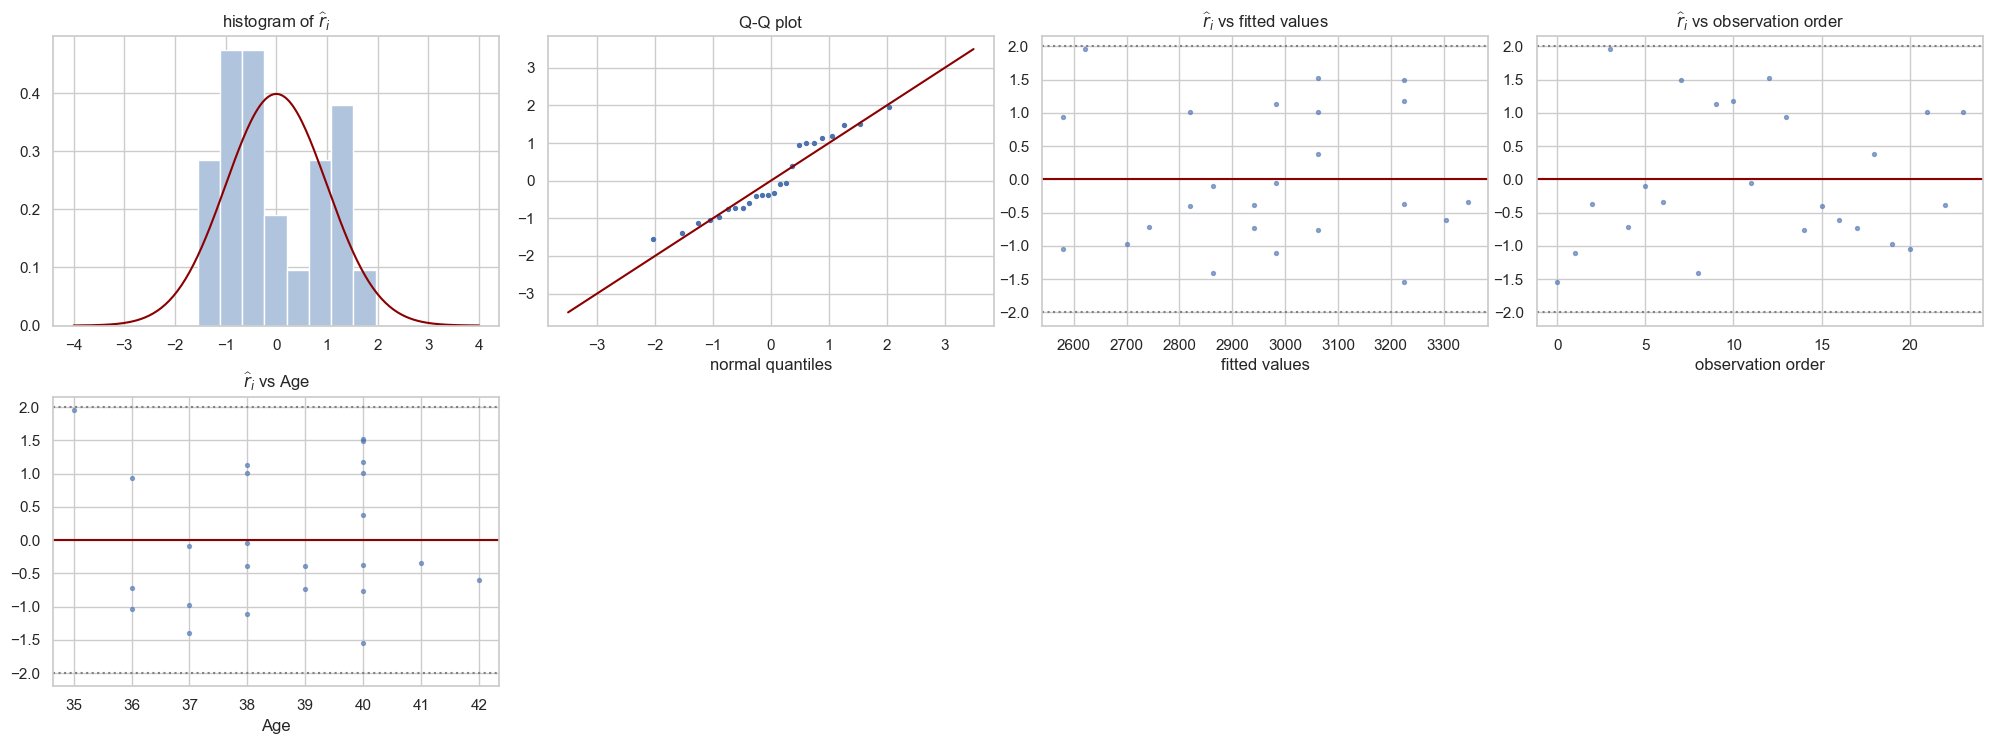

In [13]:
b_int = smf.ols('Weight ~ Age * Sex', data=birth).fit()       # R: lm(Weight ~ Age + Sex + Age:Sex)
b_par = smf.ols('Weight ~ Age + Sex', data=birth).fit()       # R: lm(Weight ~ Age + Sex)
print(b_int.summary().tables[1])
for name, fit in [('Age * Sex', b_int), ('Age + Sex', b_par)]:
    print(f'{name:10s}: s_n = {np.sqrt(fit.scale):.1f} on {int(fit.df_resid)} df,  R^2 = {fit.rsquared:.4f},  R^2_adj = {fit.rsquared_adj:.4f},'
          f'  F = {fit.fvalue:.2f} on {int(fit.df_model)} and {int(fit.df_resid)} df, p = {fit.f_pvalue:.3g}')
residual_plots(b_par, birth, ['Age'])

- Slide numbers: $F = 12.03$ on 3 and 20 df, $p = 0.0001$, $R^2 = 0.6435$, $R^2_{adj} = 0.59$.
- Parallel model: smaller $R^2$, but larger $R^2_{adj}$ (0.606) and smaller $s_n$: the interaction buys nothing.
- Residuals of the parallel model: no structure, all $|\widehat{r}_i| < 2$; the largest is the only boy born at 35 weeks (Section 4.3).

### 4.2 Sequential ANOVA (R `anova`) and the order of the terms
- Each row: increase of $\mathrm{SSR}$ when the term is added to the terms **above** it; rows add up to $\mathrm{SSR}$ (extra sums of squares, Section 6.3).

In [14]:
print('statsmodels anova_lm(Weight ~ Age * Sex):')
display(anova_lm(b_int))                                         # R: anova(mod)
birth['girl'] = (birth['Sex'] == 'girl').astype(int)             # the same dummy, as a number
b_int_num = smf.ols('Weight ~ Age + girl + Age:girl', data=birth).fit()
print('statsmodels anova_lm(Weight ~ Age + girl + Age:girl):')
display(anova_lm(b_int_num))
print(f'sum of the sequential SS = {anova_lm(b_int_num)["sum_sq"].iloc[:3].sum():.1f},  SSR = {b_int.ess:.1f}')

statsmodels anova_lm(Weight ~ Age * Sex):


,df,sum_sq,mean_sq,F,PR(>F)
Sex,1.0,7.6163e+04,7.6163e+04,2.3348,1.4218e-01
Age,1.0,1.0949e+06,1.0949e+06,33.5653,1.1425e-05
Age:Sex,1.0,6.3462e+03,6.3462e+03,0.1945,6.6389e-01
Residual,20.0,6.5242e+05,3.2621e+04,NaN,NaN


statsmodels anova_lm(Weight ~ Age + girl + Age:girl):


,df,sum_sq,mean_sq,F,PR(>F)
Age,1.0,1.0138e+06,1.0138e+06,31.0779,1.8617e-05
girl,1.0,1.5730e+05,1.5730e+05,4.8221,4.0059e-02
Age:girl,1.0,6.3462e+03,6.3462e+03,0.1945,6.6389e-01
Residual,20.0,6.5242e+05,3.2621e+04,NaN,NaN


sum of the sequential SS = 1177448.8,  SSR = 1177448.8


- **Trap:** patsy puts a factor before a numerical variable, whatever the formula says. First table: `Sex` first; the slide (R) has `Age` first.
- With the dummy as a number (`girl`) the order of the formula is kept: the slide's table.
- Both are correct, different questions; only the last row (interaction given the rest) agrees. Always check the order.

### 4.3 Example 3.4: significant model, insignificant coefficients (pp. 91–92)
- Interaction model: neither `Sex` nor `Age:Sex` significant; parallel model: `Sex` is.
- **VIF** (variance inflation factor, inflační faktor rozptylu; R `car::vif`): $\mathrm{VIF}_j = 1/(1 - R_j^2)$, $R_j^2$ of the regression of $x_j$ on the other regressors; $\mathsf{Var}\,\widehat{\beta}_j = \sigma^2\,\mathrm{VIF}_j/\mathrm{SST}_j$ (collinearity chapter).

In [15]:
b_int_c = smf.ols('Weight ~ I(Age - 38) * Sex', data=birth).fit()   # centered age, Exercise 05
display(pd.concat({'Age * Sex': vif_table(b_int), 'Age + Sex': vif_table(b_par), 'centered Age * Sex': vif_table(b_int_c)}, axis=1))
both = b_int.f_test('Sex[T.girl] = 0, Age:Sex[T.girl] = 0')
print(f'corr(girl, Age * girl) = {np.corrcoef(birth["girl"], birth["Age"] * birth["girl"])[0, 1]:.3f}')
print(f'both sex terms together: F = {float(both.fvalue):.2f}, p = {float(both.pvalue):.3f};  Sex in the parallel model: p = {b_par.pvalues["Sex[T.girl]"]:.3f}')
infl = b_par.get_influence()
i_max = int(np.argmax(infl.cooks_distance[0]))
b_drop = smf.ols('Weight ~ Age + Sex', data=birth.drop(index=i_max)).fit()
print(f'largest Cook distance: newborn {i_max} ({birth.loc[i_max, "Sex"]}, {birth.loc[i_max, "Age"]} weeks), D = {infl.cooks_distance[0][i_max]:.2f};'
      f'  without it p(Sex) = {b_drop.pvalues["Sex[T.girl]"]:.3f}')

,Age * Sex,Age + Sex,centered Age * Sex
Sex[T.girl],477.5517,1.0139,1.1103
Age,1.9644,1.0139,NaN
Age:Sex[T.girl],483.4731,NaN,NaN
I(Age - 38),NaN,NaN,1.9644
I(Age - 38):Sex[T.girl],NaN,NaN,2.1179


corr(girl, Age * girl) = 0.998
both sex terms together: F = 2.51, p = 0.107;  Sex in the parallel model: p = 0.036
largest Cook distance: newborn 3 (boy, 35 weeks), D = 0.39;  without it p(Sex) = 0.059


- `girl` and `Age·girl` correlated $0.998$ (for girls the product is $\approx 38\times$ the dummy): VIF $\approx 480$, each coefficient alone insignificant.
- Centering the age brings the VIFs to about 2 (Exercise 05); the fit is the same.
- Joint test of both sex terms: $p = 0.11$; the sex difference is spread over two parameters, one of them superfluous. Parallel model: one parameter, $p = 0.036$.
- But only just: without the one boy born at 35 weeks, $p \approx 0.06$. With $n = 24$ the evidence is weak either way.
- **Remark 3.7** (p. 91): drop insignificant variables only without collinearity and with the assumptions met; $t$-tests need care.

## 5. Example 3.5: the cement data (pp. 93–94)
- $y$: heat of hardening (cal/g), $x_1, \dots, x_4$: shares (% of weight) of four ingredients, $n = 13$ (Woods, Steinour and Starke, 1932; "Hald data").

### 5.1 Look at the data, then the model

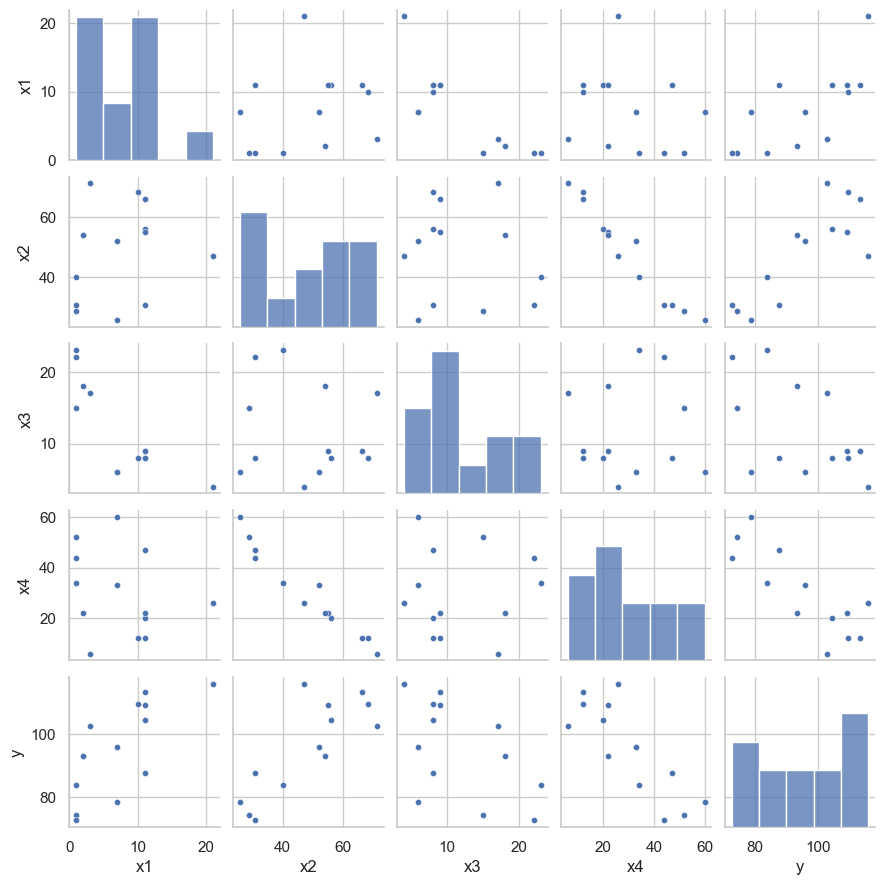

x1 + x2 + x3 + x4 per sample: [99, 97, 95, 97, 98, 97, 97, 98, 96, 98, 98, 98, 98]


In [16]:
sns.pairplot(cement, height=1.8, plot_kws={'s': 20})
plt.show()
print('x1 + x2 + x3 + x4 per sample:', (cement[['x1', 'x2', 'x3', 'x4']].sum(axis=1)).tolist())

- The shares add up to 95–99 %: $x_1 + x_2 + x_3 + x_4 \approx$ const, almost a linear relation with the intercept column.
- $x_2$ vs. $x_4$ lie almost on a line, $x_1$ vs. $x_3$ roughly.

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     62.4054     70.071      0.891      0.399     -99.179     223.989
x1             1.5511      0.745      2.083      0.071      -0.166       3.269
x2             0.5102      0.724      0.705      0.501      -1.159       2.179
x3             0.1019      0.755      0.135      0.896      -1.638       1.842
x4            -0.1441      0.709     -0.203      0.844      -1.779       1.491
x1 + x2 + x3 + x4 : s_n = 2.446,  R^2 = 0.9824,  R^2_adj = 0.9736,  F = 111.5, p = 4.8e-07
x1 + x2           : s_n = 2.406,  R^2 = 0.9787,  R^2_adj = 0.9744,  F = 229.5, p = 4.4e-09


,full model,x1 + x2
x1,38.4962,1.0551
x2,254.4232,1.0551
x3,46.8684,NaN
x4,282.5129,NaN


without intercept: coef {'x1': 2.193, 'x2': 1.153, 'x3': 0.759, 'x4': 0.486}  max p = 0.0010


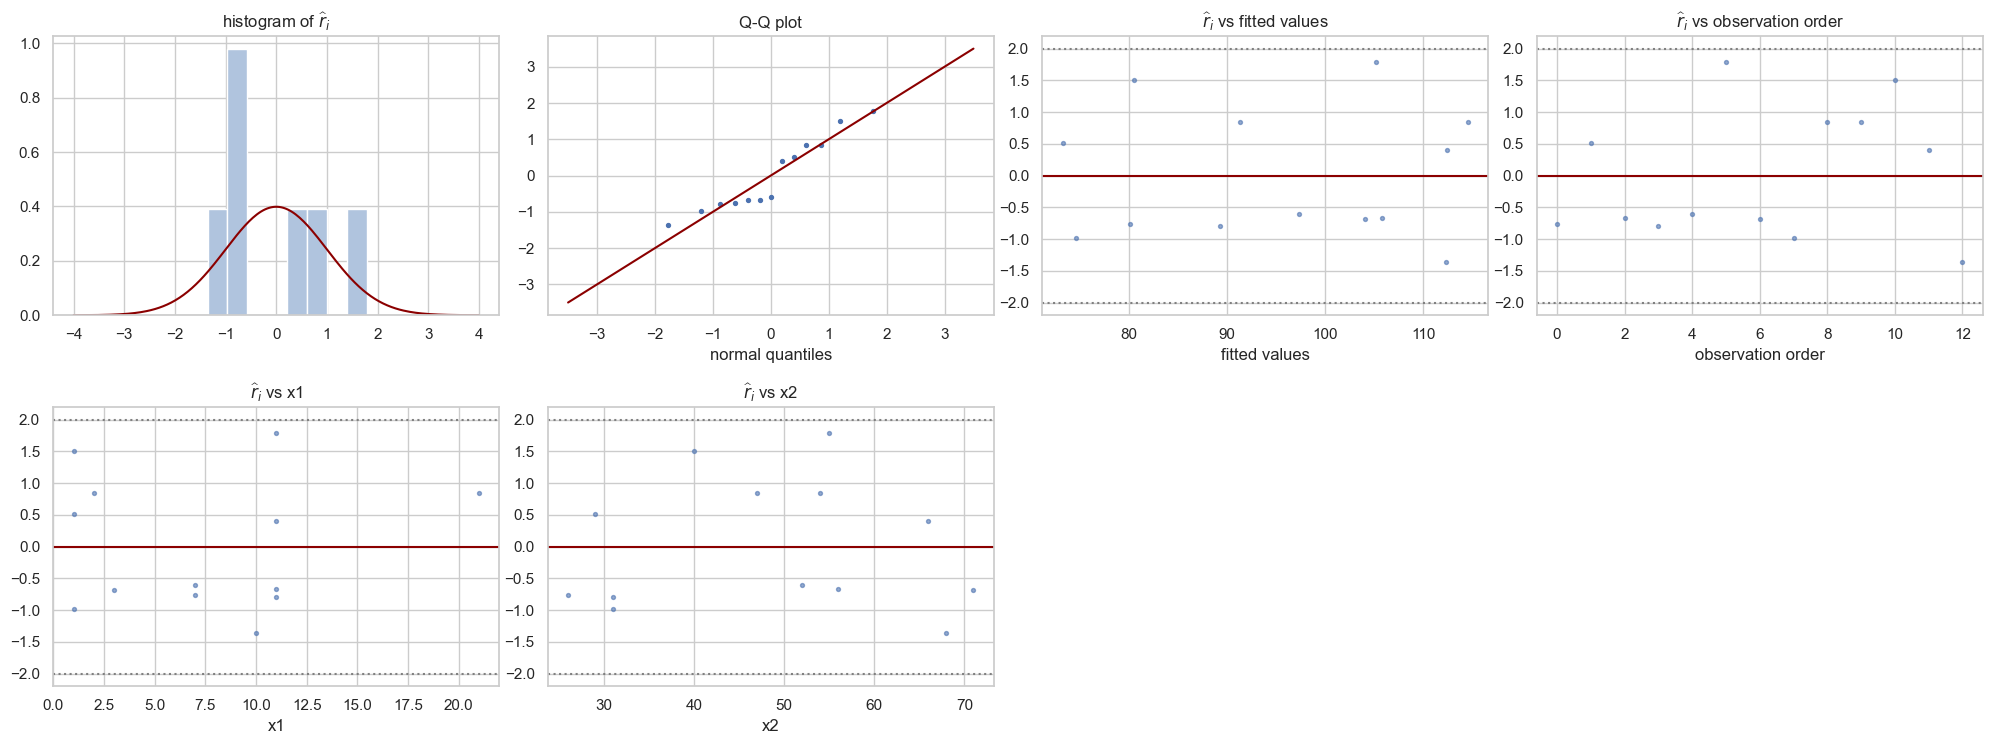

In [17]:
cem_full = smf.ols('y ~ x1 + x2 + x3 + x4', data=cement).fit()     # R: lm(y ~ x1 + x2 + x3 + x4)
cem_12 = smf.ols('y ~ x1 + x2', data=cement).fit()
cem_mix = smf.ols('y ~ x1 + x2 + x3 + x4 - 1', data=cement).fit()   # without intercept
print(cem_full.summary().tables[1])
for name, fit in [('x1 + x2 + x3 + x4', cem_full), ('x1 + x2', cem_12)]:
    print(f'{name:18s}: s_n = {np.sqrt(fit.scale):.3f},  R^2 = {fit.rsquared:.4f},  R^2_adj = {fit.rsquared_adj:.4f},  F = {fit.fvalue:.1f}, p = {fit.f_pvalue:.1e}')
display(pd.concat({'full model': vif_table(cem_full), 'x1 + x2': vif_table(cem_12)}, axis=1))
print('without intercept: coef', cem_mix.params.round(3).to_dict(), ' max p =', f'{cem_mix.pvalues.max():.4f}')
residual_plots(cem_12, cement, ['x1', 'x2'])

- Full model: $R^2 = 0.982$, $F = 111.5$, $p = 5\cdot 10^{-7}$, yet no coefficient significant at 5 %; VIF 38–283.
- `x1 + x2`: smaller $s_n$, larger $R^2_{adj}$, both coefficients highly significant, VIF 1.06; residuals without visible structure (13 points, no $|\widehat{r}_i| > 2$).
- Without intercept (a "mixture" model, the shares do the job of the constant): all four coefficients significant. The collinearity comes partly from the **parametrization**.
- **Remark 3.8** (p. 94): $F$, $R^2$, $t$ help, but not automatically. Model selection continues in Exercise 10.

### 5.2 Confidence ellipse for two coefficients
- Full model: are $\beta_2 = \beta_4 = 0$? Each $t$-test: cannot reject.
- Joint region (Theorem 3.5, point 4, with $s_n^2$; Theorem 3.10): $\{\mathbf{c}: (\mathbf{c} - \mathbf{C}\widehat{\boldsymbol{\beta}})^T[\mathbf{C}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{C}^T]^{-1}(\mathbf{c} - \mathbf{C}\widehat{\boldsymbol{\beta}}) \le 2 s_n^2 F_{1-\alpha}(2, n-m-1)\}$.
- Compared with the rectangle of two 95 % intervals and the **Bonferroni** rectangle (2 × 97.5 %).

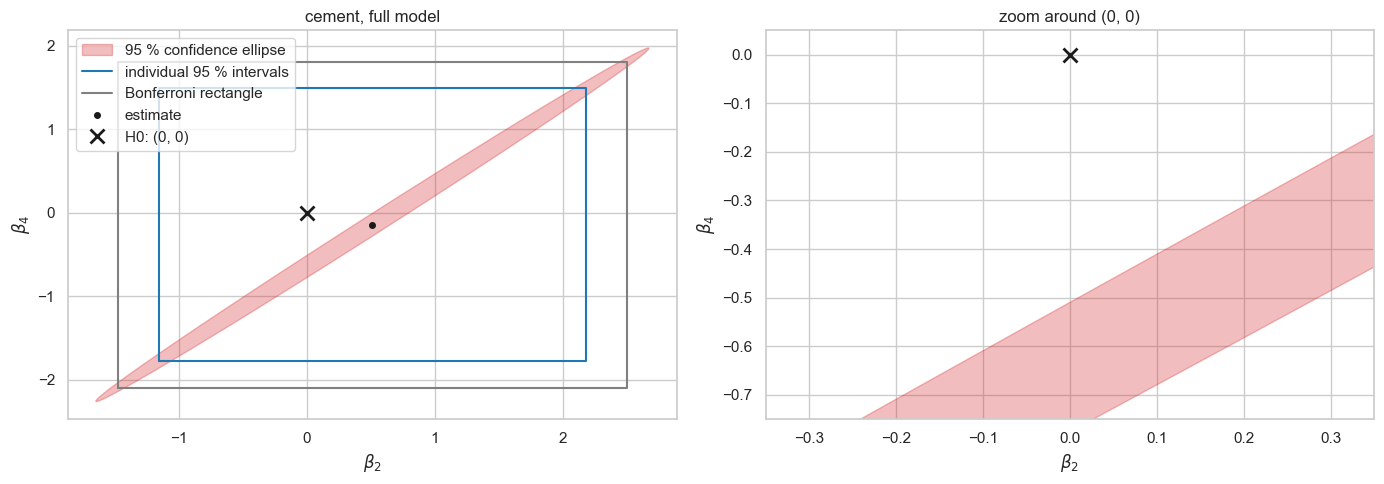

corr of the estimates: 0.998;  individual p: 0.50, 0.84;  joint F = 98.5, p = 2.3e-06


In [18]:
def confidence_ellipse(fit, names, alpha=0.05, num=400):
    """Boundary of the joint confidence region for two coefficients."""
    b = fit.params[names].to_numpy()
    V = fit.cov_params().loc[names, names].to_numpy()             # s_n^2 C (X^T X)^{-1} C^T
    radius = np.sqrt(2 * stats.f.ppf(1 - alpha, 2, fit.df_resid))
    lam, U = np.linalg.eigh(V)
    t_ = np.linspace(0, 2 * np.pi, num)
    return (b[:, None] + radius * U @ (np.sqrt(lam)[:, None] * np.vstack([np.cos(t_), np.sin(t_)]))).T


names = ['x2', 'x4']
ell = confidence_ellipse(cem_full, names)
ci = cem_full.conf_int(alpha=0.05).loc[names]                       # R: confint(mod)
ci_bonf = cem_full.conf_int(alpha=0.05 / 2).loc[names]
joint = cem_full.f_test('x2 = 0, x4 = 0')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, zoom in [(axes[0], False), (axes[1], True)]:
    ax.fill(ell[:, 0], ell[:, 1], color='tab:red', alpha=0.3, label='95 % confidence ellipse')
    for c_, col, lab in [(ci, 'tab:blue', 'individual 95 % intervals'), (ci_bonf, 'gray', 'Bonferroni rectangle')]:
        (a0, a1), (b0, b1) = c_.to_numpy()
        ax.plot([a0, a1, a1, a0, a0], [b0, b0, b1, b1, b0], color=col, label=lab)
    ax.plot(*cem_full.params[names], 'k.', ms=8, label='estimate')
    ax.plot(0, 0, 'kx', ms=10, mew=2, label='H0: (0, 0)')
    ax.set_xlabel('$\\beta_2$'); ax.set_ylabel('$\\beta_4$')
    if zoom:
        ax.set_xlim(-0.35, 0.35); ax.set_ylim(-0.75, 0.05); ax.set_title('zoom around (0, 0)')
axes[0].legend(loc='upper left'); axes[0].set_title('cement, full model')
plt.tight_layout()
plt.show()
r_est = cem_full.cov_params().loc['x2', 'x4'] / (cem_full.bse['x2'] * cem_full.bse['x4'])
print(f'corr of the estimates: {r_est:.3f};  individual p: {cem_full.pvalues["x2"]:.2f}, {cem_full.pvalues["x4"]:.2f};'
      f'  joint F = {float(joint.fvalue):.1f}, p = {float(joint.pvalue):.1e}')

- Estimates correlated $0.998$: a needle along the line where $x_2$ and $x_4$ replace each other.
- $(0, 0)$ inside both rectangles, far outside the ellipse: $x_2$ and $x_4$ cannot *both* be dropped; the data do not say which one carries the effect.
- The ellipse also leaves the rectangle along its axis: the rectangle errs in both directions.
- Uncorrelated estimates: ellipse $\approx$ rectangle, no paradox.

## 6. The general linear hypothesis (pp. 95–101)
### 6.1 Statement
- $H_0: \mathbf{C}\boldsymbol{\beta} = \mathbf{b}$, $\mathbf{C} \in \mathbb{R}^{r \times (m+1)}$, $h(\mathbf{C}) = r$: $r$ independent linear conditions.
- **Remark 3.9:** (a) $\mathbf{C} = (\mathbf{0}, \mathbf{I}_m)$: overall test; (b) one row $(0, \dots, 1, \dots, 0)$: $t$-test of $\beta_j$; (c) $\beta_2 = 0$ and $\beta_3 = \beta_4$:
$$\mathbf{C} = \begin{pmatrix} 0 & 0 & 1 & 0 & 0 \\ 0 & 0 & 0 & 1 & -1 \end{pmatrix}, \quad \mathbf{b} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}.$$
- **Full model** (plný model): no conditions; **reduced model** (redukovaný model): $\mathbf{C}\boldsymbol{\beta} = \mathbf{b}$ imposed; $\mathrm{SSE}_F \le \mathrm{SSE}_R$.
- **Theorem 3.10** (p. 98): normal errors, under $H_0$: $\ F = \dfrac{\Delta\mathrm{SSE}/r}{s_n^2} \sim F(r, n-m-1)$, $\Delta\mathrm{SSE} = \mathrm{SSE}_R - \mathrm{SSE}_F$, $s_n^2$ of the full model.
- **Lemma 3.2**, with $\mathbf{A} = [\mathbf{C}(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{C}^T]^{-1}$: $\ \widehat{\boldsymbol{\beta}}_R = \widehat{\boldsymbol{\beta}}_F - (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{C}^T\mathbf{A}(\mathbf{C}\widehat{\boldsymbol{\beta}}_F - \mathbf{b})$, $\ \Delta\mathrm{SSE} = (\mathbf{C}\widehat{\boldsymbol{\beta}}_F - \mathbf{b})^T\mathbf{A}(\mathbf{C}\widehat{\boldsymbol{\beta}}_F - \mathbf{b})$.

### 6.2 Remark 3.9 (c) on the cement data, three ways
- Under $H_0$: $y = \beta_0 + \beta_1x_1 + \beta_3(x_3 + x_4) + e$, an ordinary regression on $x_1$ and $x_3 + x_4$.

In [19]:
Xcem = dmatrices('y ~ x1 + x2 + x3 + x4', data=cement, return_type='dataframe')[1].to_numpy()
XtX_inv_cem = np.linalg.inv(Xcem.T @ Xcem)
C_mat = np.array([[0, 0, 1, 0, 0],                 # not C: that name is patsy's C() in formulas
                  [0, 0, 0, 1, -1]])
b_vec = np.zeros(2)
r = C_mat.shape[0]

# 1) Lemma 3.2 from the full fit
bF = cem_full.params.to_numpy()
A = np.linalg.inv(C_mat @ XtX_inv_cem @ C_mat.T)
d = C_mat @ bF - b_vec
bR_lemma = bF - XtX_inv_cem @ C_mat.T @ A @ d
dSSE_lemma = d @ A @ d
F_ = (dSSE_lemma / r) / cem_full.scale

# 2) the reduced model fitted directly
cem_red = smf.ols('y ~ x1 + I(x3 + x4)', data=cement).fit()
print('beta_R, Lemma 3.2      :', bR_lemma.round(4))
print('reduced model directly :', cem_red.params.round(4).to_dict())
print(f'Delta SSE: Lemma {dSSE_lemma:.6f}, SSE_R - SSE_F {cem_red.ssr - cem_full.ssr:.6f};  F = {F_:.4f}, p = {stats.f.sf(F_, r, cem_full.df_resid):.4f}')

# 3) statsmodels: matrices, a string of conditions, two fitted models
print(cem_full.f_test((C_mat, b_vec)))
print(cem_full.f_test('x2 = 0, x3 = x4'))                          # R: car::linearHypothesis(mod, c("x2 = 0", "x3 = x4"))
display(anova_lm(cem_red, cem_full))                              # R: anova(mod_reduced, mod_full)

beta_R, Lemma 3.2      : [116.2618   0.8347  -0.      -0.648   -0.648 ]
reduced model directly : {'Intercept': 116.2618, 'x1': 0.8347, 'I(x3 + x4)': -0.648}
Delta SSE: Lemma 11.450409, SSE_R - SSE_F 11.450409;  F = 0.9569, p = 0.4240
<F test: F=0.9569192081966547, p=0.4240261135731097, df_denom=8, df_num=2>
<F test: F=0.9569192081966547, p=0.4240261135731097, df_denom=8, df_num=2>


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,10.0,59.3140,0.0,NaN,NaN,NaN
1,8.0,47.8636,2.0,11.4504,0.9569,0.424


- Lemma 3.2 = direct fit of the reduced model ($\widehat{\beta}_3 = \widehat{\beta}_4$ = coefficient of $x_3 + x_4$).
- $F = 0.96$, $p = 0.42$: dropping $x_2$ and one common coefficient for $x_3, x_4$ is compatible with the data.
- `anova_lm(reduced, full)` needs a reduced model writable as a formula; the matrix form always works.

### 6.3 Special cases and the extra sum of squares
- Overall test (Example 3.6, p. 97): reduced model $Y = \beta_0 + e$, $\mathrm{SSE}_R = \mathrm{SST}$, $\Delta\mathrm{SSE} = \mathrm{SSR}$.
- One coefficient: $F = T_j^2$ (the $t$-test keeps the sign and allows one-sided alternatives).
- **Remark 3.10** (p. 100): $\Delta\mathrm{SSE} = \mathrm{SSR}_F - \mathrm{SSR}_R$, the **extra sum of squares** (extra regresní součet čtverců); adding terms one by one splits $\mathrm{SSR}$ into $\mathrm{SS}(x_1)$, $\mathrm{SS}(x_2 \mid x_1)$, ...: the sequential table of Section 4.2.

In [20]:
full_vs_const = anova_lm(smf.ols('y ~ 1', data=cement).fit(), cem_full)
print(f'overall test as a general hypothesis: F = {full_vs_const["F"].iloc[1]:.2f}, summary: F = {cem_full.fvalue:.2f}')
print(f'x4 = 0: F = {float(cem_full.f_test("x4 = 0").fvalue):.5f}, T^2 = {cem_full.tvalues["x4"] ** 2:.5f}')

# Example 3.7 (p. 101): the interaction of the birth weight model
display(anova_lm(b_par, b_int))                                    # R: anova(mod0, mod)
print(f't^2 of the interaction = {b_int.tvalues["Age:Sex[T.girl]"] ** 2:.4f},  extra SS = SSR_F - SSR_R = {b_int.ess - b_par.ess:.1f}')

# Example 3.8 (p. 101): sequential tables of the cement data in two orders
seq_1234 = anova_lm(cem_full)
seq_4321 = anova_lm(smf.ols('y ~ x4 + x3 + x2 + x1', data=cement).fit())
display(pd.concat({'order x1, x2, x3, x4': seq_1234[['sum_sq', 'F', 'PR(>F)']],
                   'order x4, x3, x2, x1': seq_4321[['sum_sq', 'F', 'PR(>F)']]}, axis=1))
print(f'SSR = {cem_full.ess:.1f};  sums of the sequential SS: {seq_1234["sum_sq"].iloc[:4].sum():.1f}, {seq_4321["sum_sq"].iloc[:4].sum():.1f}')

overall test as a general hypothesis: F = 111.48, summary: F = 111.48
x4 = 0: F = 0.04128, T^2 = 0.04128


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,21.0,658770.7468,0.0,NaN,NaN,NaN
1,20.0,652424.5218,1.0,6346.2249,0.1945,0.6639


t^2 of the interaction = 0.1945,  extra SS = SSR_F - SSR_R = 6346.2


order x1, x2, x3, x4                       order x4, x3, x2, x1  \
                       sum_sq         F      PR(>F)               sum_sq   
x1                  1450.0763  242.3679  2.8876e-07              25.9509   
x2                  1207.7823  201.8705  5.8633e-07             101.9235   
x3                     9.7939    1.6370  2.3660e-01             708.1289   
x4                     0.2470    0.0413  8.4407e-01            1831.8962   
Residual              47.8636       NaN         NaN              47.8636   

                                
                 F      PR(>F)  
x1          4.3375  7.0822e-02  
x2         17.0356  3.3102e-03  
x3        118.3577  4.5094e-06  
x4        306.1859  1.1613e-07  
Residual       NaN         NaN

SSR = 2667.9;  sums of the sequential SS: 2667.9, 2667.9


- Example 3.7: $F = 0.1945 = t^2$ of the interaction, extra SS $= 6346$ (slide).
- Example 3.8: both orders add up to $\mathrm{SSR} = 2667.9$ (slide), but the split differs: $x_4$ first takes $1832$, last only $0.25$.
- "How much does $x_j$ explain" has no answer without "given which other variables". The last row = $t$-test of the last term, squared.

## 7. Prediction (pp. 102–106)
### 7.1 Intervals in matrix form
- New point $\mathbf{x}_0 = (1, x_{0,1}, \dots, x_{0,m})^T$; $\widehat{Y}_{\mathbf{x}_0} = \mathbf{x}_0^T\widehat{\boldsymbol{\beta}}$.
- **Variance of the prediction** (rozptyl predikce): $\mathsf{Var}\,\widehat{Y}_{\mathbf{x}_0} = \sigma^2\,\mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0$; for $\mathbf{x}_0 = \mathbf{x}_i$ it is $\sigma^2 h_{ii}$.
- **CI for $\mathsf E\,Y_{\mathbf{x}_0}$**: $\ \widehat{Y}_{\mathbf{x}_0} \pm t_{1-\alpha/2}(n-m-1)\,s_n\sqrt{\mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0}$.
- **Prediction interval for $Y_{\mathbf{x}_0}$**: $\ \widehat{Y}_{\mathbf{x}_0} \pm t_{1-\alpha/2}(n-m-1)\,s_n\sqrt{1 + \mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0}$.
- A car of 3000 lb and 100 hp, model of Section 3:

In [21]:
XtX_inv = np.linalg.inv(X.T @ X)
s_n = np.sqrt(model.scale)
x0 = np.array([1.0, 3000.0, 100.0])
h0 = x0 @ XtX_inv @ x0
y0 = x0 @ model.params.to_numpy()
t_q = stats.t.ppf(0.975, model.df_resid)
print(f'y_hat_0 = {y0:.3f} L/100 km,  x0^T (X^T X)^-1 x0 = {h0:.5f}')
print(f'95 % CI for E Y_0: ({y0 - t_q * s_n * np.sqrt(h0):.3f}, {y0 + t_q * s_n * np.sqrt(h0):.3f})')
print(f'95 % PI for Y_0  : ({y0 - t_q * s_n * np.sqrt(1 + h0):.3f}, {y0 + t_q * s_n * np.sqrt(1 + h0):.3f})')
new = pd.DataFrame({'weight': [3000], 'horsepower': [100]})
pred = model.get_prediction(new)                     # R: predict(mod, new, interval = "confidence" / "prediction")
display(pred.summary_frame(alpha=0.05))

# check against the data: cars close to x0
near = cars[cars['weight'].between(2750, 3250) & cars['horsepower'].between(90, 110)]
print(f'{len(near)} cars with 2750-3250 lb and 90-110 hp: mean {near["l_per_100km"].mean():.2f} L/100 km (se {near["l_per_100km"].sem():.2f})')
model_mpg = smf.ols('mpg ~ weight + horsepower', data=cars).fit()
fr_mpg = model_mpg.get_prediction(new).summary_frame()
print(f'the same with mpg as the response: model {fr_mpg["mean"].iloc[0]:.2f} mpg (CI {fr_mpg["mean_ci_lower"].iloc[0]:.2f} to {fr_mpg["mean_ci_upper"].iloc[0]:.2f}),'
      f' neighbours {near["mpg"].mean():.2f} mpg (se {near["mpg"].sem():.2f})')

y_hat_0 = 11.147 L/100 km,  x0^T (X^T X)^-1 x0 = 0.00275
95 % CI for E Y_0: (10.973, 11.321)
95 % PI for Y_0  : (7.825, 14.468)


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,11.147,0.0884,10.9731,11.3209,7.8255,14.4685


29 cars with 2750-3250 lb and 90-110 hp: mean 11.44 L/100 km (se 0.26)
the same with mpg as the response: model 23.53 mpg (CI 23.09 to 23.96), neighbours 20.88 mpg (se 0.51)


- Manual = `get_prediction` (`mean_se` $= s_n\sqrt{h_0}$, `se_obs` $= s_n\sqrt{1 + h_0}$).
- CI narrow (uncertainty of $\widehat{\boldsymbol{\beta}}$, shrinks with $n$), PI wide (scatter of one car, does not shrink).
- The neighbours agree with the L/100 km model. With `mpg` (U-shaped residuals) the CI misses the neighbours by about 2.5 mpg: **a CI is only as good as the model**.
- The spread of the residuals grows with the consumption: one $s_n$ makes the PI too wide for economical and too narrow for thirsty cars (remedies in Exercise 09).

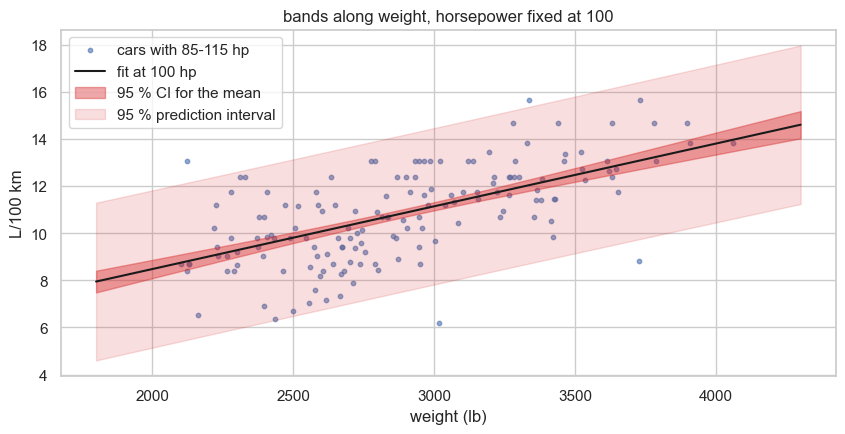

In [22]:
grid = pd.DataFrame({'weight': np.linspace(1800, 4300, 100), 'horsepower': 100})
fr = model.get_prediction(grid).summary_frame()
similar = cars[cars['horsepower'].between(85, 115)]
plt.figure(figsize=(10, 4.5))
plt.scatter(similar['weight'], similar['l_per_100km'], s=10, alpha=0.6, label='cars with 85-115 hp')
plt.plot(grid['weight'], fr['mean'], color='k', label='fit at 100 hp')
plt.fill_between(grid['weight'], fr['mean_ci_lower'], fr['mean_ci_upper'], alpha=0.4, color='tab:red', label='95 % CI for the mean')
plt.fill_between(grid['weight'], fr['obs_ci_lower'], fr['obs_ci_upper'], alpha=0.15, color='tab:red', label='95 % prediction interval')
plt.xlabel('weight (lb)'); plt.ylabel('L/100 km'); plt.legend(); plt.title('bands along weight, horsepower fixed at 100')
plt.show()

**Dictionary** (names differ between the lecture, R, statsmodels and English texts):

| | CI for $\mathsf E\,Y_{\mathbf{x}_0}$ | prediction interval for $Y_{\mathbf{x}_0}$ |
|---|---|---|
| Czech | interval spolehlivosti pro $\mathsf E\,Y_{\mathbf{x}_0}$ | interval predikce |
| English | confidence interval for the mean response | prediction interval |
| standard error | $s_n\sqrt{\mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0}$; Lecture 4 called it "standardní chyba predikce v bodě $x_0$" | $s_n\sqrt{1 + \mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0}$; English "standard error of prediction" |
| R | `predict(..., interval = "confidence")`, `se.fit` | `predict(..., interval = "prediction")` |
| statsmodels | `mean_ci_lower/upper`, `mean_se` | `obs_ci_lower/upper`, `se_obs` (attribute only) |

- `obs_ci` sounds like a confidence interval but **is the prediction interval**.
- Bands are pointwise; `seaborn.regplot`, `ggplot2::geom_smooth` draw only the CI band.

### 7.2 Extrapolation: Remark 3.11 (p. 105)
- Prediction variance $\propto \mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0$; the data points with the largest $h_{ii}$ mark the border of reliable prediction.
- Admissible region: $\mathbf{x}^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x} \le \max_i h_{ii}$, an ellipsoid (picture p. 106).
- "Inside the range of each variable" is not "inside the data".

In [23]:
h = np.einsum('ij,jk,ik->i', X, XtX_inv, X)
i_max = int(np.argmax(h))
print('largest leverage:', cars.loc[i_max, ['name', 'model_year', 'weight', 'displacement', 'horsepower']].to_dict(), f' h = {h[i_max]:.4f}')
print('other cars with an engine of 400 cu in or more:')
display(cars[(cars['displacement'] >= 400) & (cars.index != i_max)][['name', 'model_year', 'weight', 'displacement', 'horsepower']]
        .sort_values('weight').head(4))
keep = np.arange(n) != i_max
X_k = X[keep]
XtX_inv_k = np.linalg.inv(X_k.T @ X_k)
h_k = np.einsum('ij,jk,ik->i', X_k, XtX_inv_k, X_k)
print(f'max h_ii: {h.max():.4f} with this car, {h_k.max():.4f} without it')

largest leverage: {'name': 'buick estate wagon (sw)', 'model_year': 70, 'weight': 3086, 'displacement': 455.0, 'horsepower': 225.0}  h = 0.0950
other cars with an engine of 400 cu in or more:


,name,model_year,weight,displacement,horsepower
12,chevrolet monte carlo,70,3761,400.0,150.0
227,pontiac grand prix lj,77,4220,400.0,180.0
115,pontiac grand prix,73,4278,400.0,230.0
7,plymouth fury iii,70,4312,440.0,215.0


max h_ii: 0.0950 with this car, 0.0509 without it


- The point that defines $\max h_{ii}$ is a 1970 Buick estate wagon: 455 cu in and 225 hp at 3086 lb, while all other cars with such engines weigh 3760–5000 lb. Most likely a **data error** (weight); without it $\max h_{ii}$ halves.
- An analyst checks such a record before letting it define anything. Below both regions are drawn.

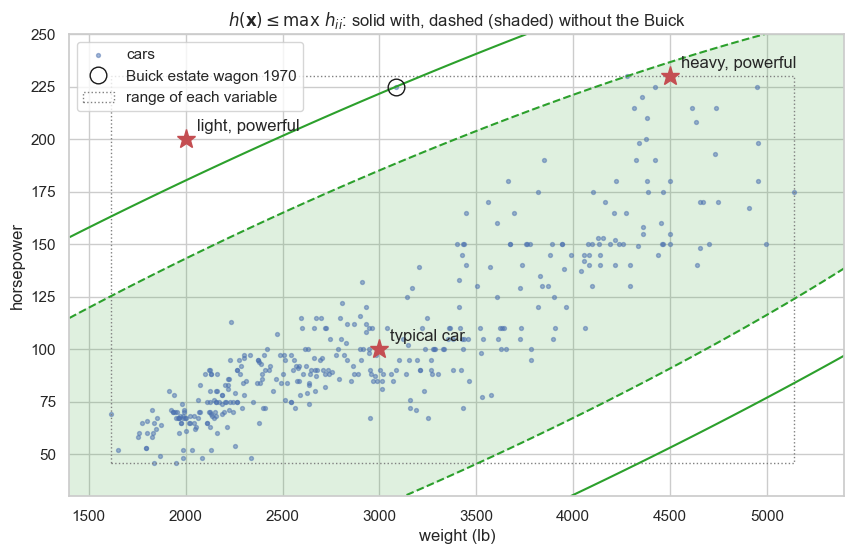

,weight,horsepower,h0,h0 / max h_ii,"h0 / max h_ii, without the Buick",prediction,CI width,PI width
typical car,3000,100,0.003,0.029,0.054,11.147,0.348,6.643
"heavy, powerful",4500,230,0.040,0.426,0.862,19.835,1.334,6.767
"light, powerful",2000,200,0.128,1.351,2.780,12.092,2.377,7.047


In [24]:
w_grid, hp_grid = np.meshgrid(np.linspace(1400, 5400, 300), np.linspace(30, 250, 300))
x_grid = np.stack([np.ones_like(w_grid), w_grid, hp_grid], axis=-1)
h_grid = np.einsum('...j,jk,...k->...', x_grid, XtX_inv, x_grid)
h_grid_k = np.einsum('...j,jk,...k->...', x_grid, XtX_inv_k, x_grid)

points = pd.DataFrame({'weight': [3000, 4500, 2000], 'horsepower': [100, 230, 200]},
                      index=['typical car', 'heavy, powerful', 'light, powerful'])
P0 = np.column_stack([np.ones(3), points.to_numpy(dtype=float)])
fr = model.get_prediction(points).summary_frame()
points['h0'] = np.einsum('ij,jk,ik->i', P0, XtX_inv, P0)
points['h0 / max h_ii'] = points['h0'] / h.max()
points['h0 / max h_ii, without the Buick'] = np.einsum('ij,jk,ik->i', P0, XtX_inv_k, P0) / h_k.max()
points['prediction'] = fr['mean'].to_numpy()
points['CI width'] = (fr['mean_ci_upper'] - fr['mean_ci_lower']).to_numpy()
points['PI width'] = (fr['obs_ci_upper'] - fr['obs_ci_lower']).to_numpy()

fig, ax = plt.subplots(figsize=(10, 6))
ax.contour(w_grid, hp_grid, h_grid, levels=[h.max()], colors='tab:green')
ax.contourf(w_grid, hp_grid, h_grid_k, levels=[0, h_k.max()], colors=['tab:green'], alpha=0.15)
ax.contour(w_grid, hp_grid, h_grid_k, levels=[h_k.max()], colors='tab:green', linestyles='--')
ax.scatter(cars['weight'], cars['horsepower'], s=8, alpha=0.5, label='cars')
ax.plot(cars.loc[i_max, 'weight'], cars.loc[i_max, 'horsepower'], 'o', mfc='none', mec='k', ms=12, label='Buick estate wagon 1970')
ax.add_patch(plt.Rectangle((cars['weight'].min(), cars['horsepower'].min()), np.ptp(cars['weight']), np.ptp(cars['horsepower']),
                           fill=False, ls=':', color='gray', label='range of each variable'))
for name, row in points.iterrows():
    ax.plot(row['weight'], row['horsepower'], 'r*', ms=14)
    ax.annotate(name, (row['weight'], row['horsepower']), xytext=(8, 6), textcoords='offset points')
ax.set_xlabel('weight (lb)'); ax.set_ylabel('horsepower')
ax.set_title('$h(\\mathbf{x}) \\leq \\max\\ h_{ii}$: solid with, dashed (shaded) without the Buick')
ax.legend(loc='upper left')
plt.show()
display(points.round(3))

- Weight and power correlated $0.86$: the cars fill an inclined band, the region is an inclined ellipse.
- Light car with 200 hp: inside both ranges, outside the data (about 3× the largest leverage without the Buick). The CI is several times wider than for the typical car and still assumes the plane holds where no car was observed.
- Heavy powerful car: at the edge, but along the band; inside the region.
- The PI width hardly changes (it is dominated by $s_n$): **a wide PI does not warn of extrapolation, $h_0$ does**.

## 8. Individual work: fuel consumption of the 2004 cars
`carsdata2.csv` (separator `;`): 428 car models sold in the USA in 2004.
- `RetailPrice`, `DealerCost` (USD), `EngineSize` (L), `Cyl`, `HP`, `CityMPG`, `HwyMPG`, `Weight` (lb), `WheelBase`, `Len`, `Width` (in),
- type dummies `Sedan`, `Sports`, `SUV`, `Wagon`, `Minivan`, `Pickup`; drive dummies `AWD`, `RWD` (neither = front-wheel drive).
- The data contain a few coding errors. If you find one, fix it and say so.

Short conclusions after each step.
1. **Data.** Create `consumption` $= 235.215/\big((\text{CityMPG} + \text{HwyMPG})/2\big)$ (L/100 km), a factor `type` (check: exactly one type per car) and `drive` (`FWD`, `AWD`, `RWD`). Look at the cars with the lowest and the highest consumption, at the cars with missing values and at duplicated rows. Does every car belong to the population "ordinary petrol cars"? Decide what to keep.
2. **Plots.** Consumption against `Weight`, `HP`, `EngineSize` (colour = type), and `mpg` against `Weight`. Why is L/100 km the better response for a linear model?
3. **Model and residuals.** Fit `consumption ~ Weight + HP + EngineSize + type + drive` (references `Sedan`, `FWD`). Residual plots before any test: largest residuals (which cars?), does the spread depend on the type?
4. **ANOVA and intervals.** ANOVA table by hand, $F$, $p$, $R^2$, $R^2_{adj}$; $s_n$ in L/100 km and in % of the mean consumption. 95 % CI for the `Weight` coefficient by hand; interpret per 1000 lb and compare with the simple regression `consumption ~ Weight`.
5. **Hypotheses.** (a) Does the type matter at all? $\mathbf{C}$, $r$, full vs. reduced model, `f_test`; compare with the $t$-tests of the type dummies. (b) $\beta_{AWD} = \beta_{RWD}$? $\Delta\mathrm{SSE}$ and $F$ by Lemma 3.2, `f_test`, and $F = T^2$ after changing the reference level to `RWD`.
6. **Prediction.** A front-wheel drive sedan with the median weight, power and engine size of such sedans: CI for the mean and PI for one car, by hand and by `get_prediction`. Compare with a few real cars close to $\mathbf{x}_0$.
7. **Extrapolation.** A planned rear-wheel drive sports car: 2500 lb, 450 hp, 6.0 L. Inside the range of each variable? $\mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0$ vs. $\max h_{ii}$; plot `HP` against `Weight` with $\mathbf{x}_0$. Repeat Steps 6 and 7 with `np.log(consumption) ~ np.log(Weight) + np.log(HP) + np.log(EngineSize) + type + drive`. Where do the two models agree, where not, and why?

In [25]:
url_cars04 = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/carsdata2.csv'
cars04 = pd.read_csv(url_cars04, sep=';')
cars04.head()

,Name,Sedan,Sports,SUV,Wagon,Minivan,Pickup,AWD,RWD,RetailPrice,DealerCost,EngineSize,Cyl,HP,CityMPG,HwyMPG,Weight,WheelBase,Len,Width
0,Acura 3.5 RL 4dr,1,0,0,0,0,0,0,0,43755,39014,3.5,6,225,18.0,24.0,3880.0,115.0,197.0,72.0
1,Acura 3.5 RL w/Navigation 4dr,1,0,0,0,0,0,0,0,46100,41100,3.5,6,225,18.0,24.0,3893.0,115.0,197.0,72.0
2,Acura MDX,0,0,1,0,0,0,1,0,36945,33337,3.5,6,265,17.0,23.0,4451.0,106.0,189.0,77.0
3,Acura NSX coupe 2dr manual S,0,1,0,0,0,0,0,1,89765,79978,3.2,6,290,17.0,24.0,3153.0,100.0,174.0,71.0
4,Acura RSX Type S 2dr,1,0,0,0,0,0,0,0,23820,21761,2.0,4,200,24.0,31.0,2778.0,101.0,172.0,68.0


In [26]:
# your solution


## 9. What to remember
- Overall $F = \dfrac{\mathrm{SSR}/m}{\mathrm{SSE}/(n-m-1)} \sim F(m, n-m-1)$ under $H_0$ (Theorem 3.9); large $n$: works without normality. statsmodels: `ssr` = SSE, `ess` = SSR.
- $R^2$ never decreases; $R^2_{adj} = 1 - s_n^2/s_y^2$ is right on average but noisy with few residual df.
- Significant model, insignificant coefficients: correlated regressors (VIF); answer joint questions jointly (joint $F$-test, ellipse).
- $\mathbf{C}\boldsymbol{\beta} = \mathbf{b}$: full vs. reduced model, $F = \dfrac{\Delta\mathrm{SSE}/r}{s_n^2}$ (Theorem 3.10); Lemma 3.2 from the full fit; overall test and $F = T_j^2$ are special cases. `f_test`, `anova_lm(reduced, full)`; R `anova(m0, m)`, `car::linearHypothesis`.
- Sequential ANOVA depends on the order of the terms; patsy may reorder.
- CI for the mean: $s_n\sqrt{\mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0}$; PI: $s_n\sqrt{1 + \dots}$; `obs_ci` is the PI.
- Extrapolation: compare $\mathbf{x}_0^T(\mathbf{X}^T\mathbf{X})^{-1}\mathbf{x}_0$ with $\max h_{ii}$, and check the point that sets $\max h_{ii}$.
- No test or interval without a look at the data and the residuals first.